# Mini-Project #1 — Q1: Neural Spike Patterns



## A. Constructing the models

### How spike times are generated

For the regular neuron, I used the arange command so I can make an array where the neuron fires at a constant interval.

For the irregular neuron, I used the random.uniform command and then used the cumsum command so I can make an array where the firing rate of the neuron is inconsistent.

For the bursting neuron, I used a random uniform and cumsum array and moved it in time twice, creating set quiet periods when there is no firing. I set the time by hand and added all the arrays together using the concatenate command.

### Which parameters control the firing pattern

The parameters that control the firing pattern are, for the first neuron, the starting point, which I set to zero seconds; the finishing point, which I set to 5 seconds; and how often I want the neuron to fire, which I set to every 0.2 seconds.

For the irregular neuron, I chose how many spaces I wanted between the different firings, which I set to 80, and I set the difference between each firing to be between 0-0.3 seconds.

For the bursting neuron, I set the number of spaces between spikes to 30 and the difference between each firing to be between 0-0.05 seconds. This will be one cluster.

I made two other clusters using the first cluster, adding 2 seconds to it to create the second cluster and adding 4 seconds to create the third cluster. That made all the clusters look alike and created "quiet" periods with no firing. After doing so, I concatenated the three arrays into one array using the concatenate command.

### Which aspects are deterministic and which are stochastic

The regular neuron's shooting is deterministic; we can know when the neuron will fire. The irregular neuron is stochastic; it follows a random shooting pattern, and we don't know when it will fire. The bursting neuron contains both: the clusters themselves are stochastic, but the difference between the starting times of the clusters is deterministic.

### How spike times are valid and chronologically ordered

I can ensure that using different methods in each neuron.

For the regular neuron, using np.arange, I chose how often the neuron will fire using a set number, which for me was 0.2 seconds. I also set when I want the neuron to start firing (0 seconds) and when to stop (5 seconds).

For the irregular neuron, the firing is supposed to be random, so I used the random.uniform command and the cumsum command. The cumsum command makes sure that the firing is in chronological order. The chronological order is maintained by the cumsum command's ability to sum each number I get from the random.uniform command and create numbers in ascending order. I also made sure that the neuron will not fire after 5 seconds using random_spikes = random_spikes[random_spikes <= 5]

For the bursting neuron, I used three arrays. The first one was created using random.uniform, the second one was created by adding 2 seconds to the first array, and the third one was created by adding 4 seconds to the first array. Then I used the concatenate command, creating "quiet" spaces between the different clusters. Then I made the three arrays into one single array using the concatenate command. I also made sure that the neuron will not fire after 5 seconds using bursting= bursting[bursting <= 5].

### Simulation code



In [1]:
import numpy as np
import matplotlib.pyplot as mat

# Regular neuron
regular_spikes = np.arange(0, 5, 0.2)


In [2]:
# Irregular neuron
random = np.random.default_rng(7)
randomm = random.uniform(0, 0.3, 80)
random_spikes = np.cumsum(randomm)
random_spikes = random_spikes[random_spikes <= 5]


In [3]:
# Bursting neuron
randomm = random.uniform(0, 0.05, 30)
bursting_spikes = np.cumsum(randomm)
bursting_spikes2 = bursting_spikes + 2
bursting_spikes3 = bursting_spikes2 + 2
bursting = np.concatenate((bursting_spikes, bursting_spikes2, bursting_spikes3))
bursting = bursting[bursting <= 5]


### Individual spike plots


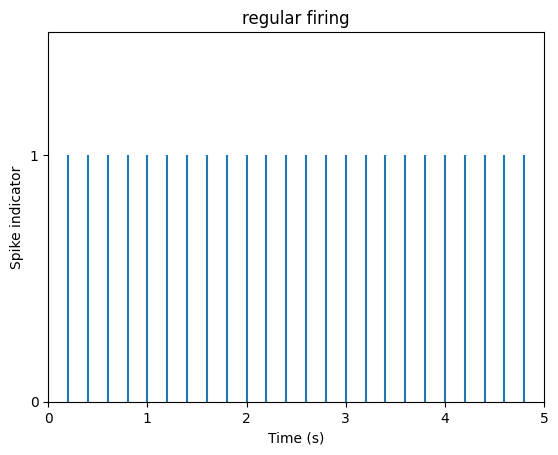

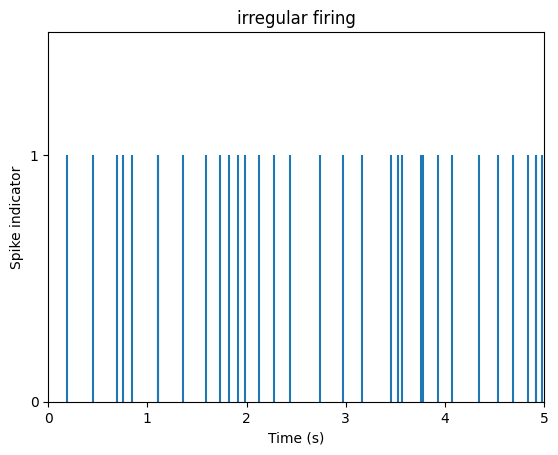

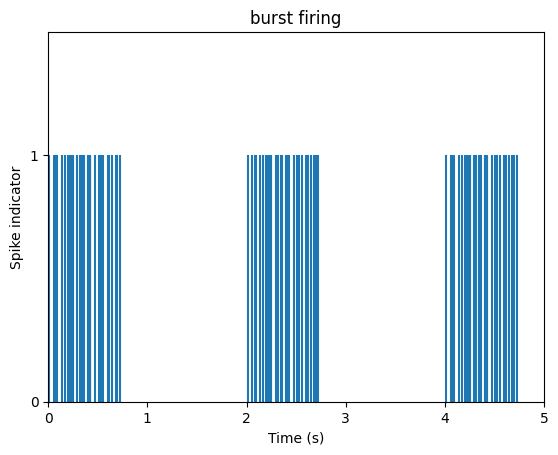

In [4]:
for times, name in [
    (regular_spikes, "regular firing"),
    (random_spikes, "irregular firing"),
    (bursting, "burst firing"),
]:
    mat.figure()
    mat.vlines(times, 0, 1)
    mat.xlim(0, 5)
    mat.ylim(0, 1.5)
    mat.yticks([0, 1])
    mat.xlabel("Time (s)")
    mat.ylabel("Spike indicator")
    mat.title(name)
    mat.show()


## B. Investigating the firing patterns




### Inter-spike intervals (ISI)

In [5]:
regularISI = np.diff(regular_spikes)
irregularISI = np.diff(random_spikes)
burstingISI = np.diff(bursting)


### Raster plot — all three neurons on the same time axis

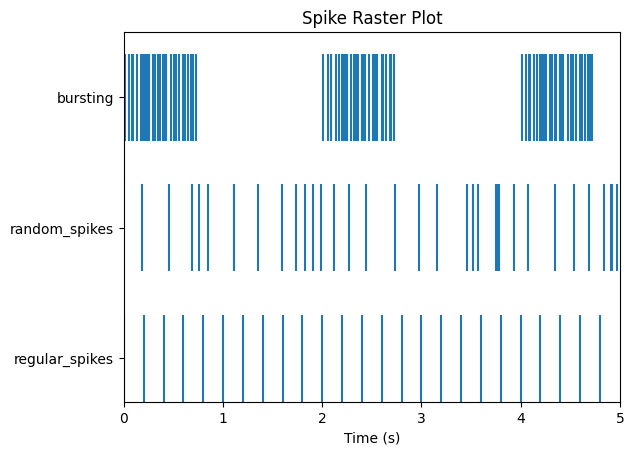

In [6]:
mat.figure()
mat.eventplot([regular_spikes, random_spikes, bursting], lineoffsets=[1, 4, 7], linelengths=2)
mat.yticks([1, 4, 7], ["regular_spikes", "random_spikes", "bursting"])
mat.xlim(0, 5)
mat.ylim(0, 8.5)
mat.xlabel("Time (s)")
mat.title("Spike Raster Plot")
mat.show()


### ISI plots by sequence index



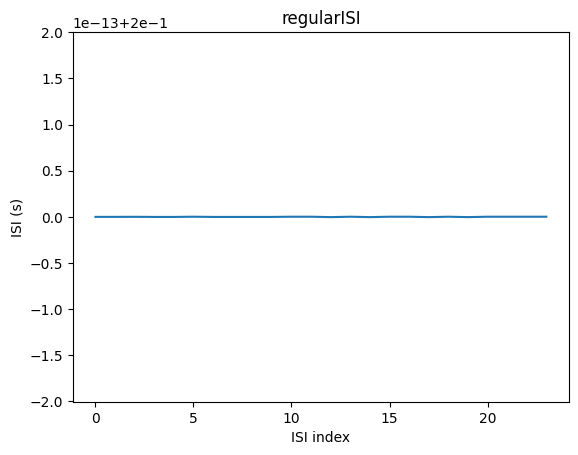

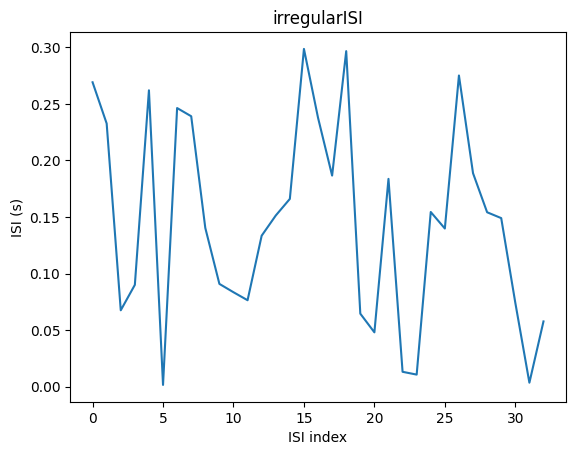

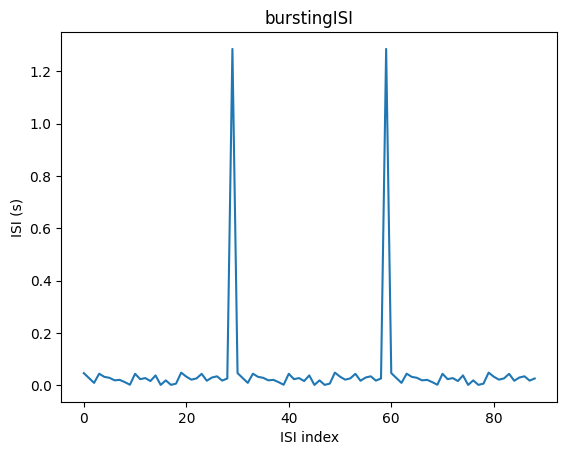

In [7]:
for isi, title in [
    (regularISI, "regularISI"),
    (irregularISI, "irregularISI"),
    (burstingISI, "burstingISI"),
]:
    mat.figure()
    mat.plot(isi)
    mat.xlabel("ISI index")
    mat.ylabel("ISI (s)")
    mat.title(title)
    mat.show()


### ISI histograms

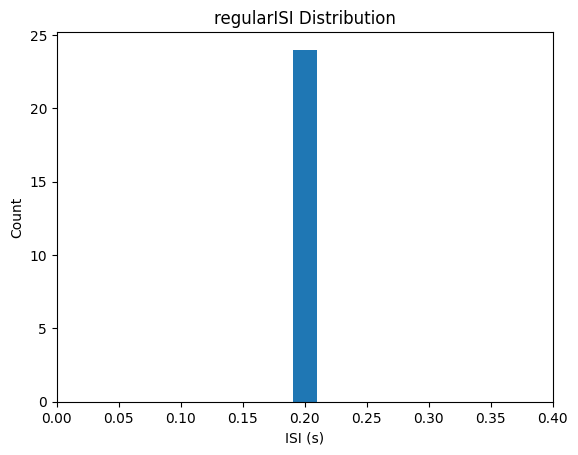

In [8]:
mat.figure()
mat.hist(np.round(regularISI, 3), bins=[0.19, 0.21])
mat.xlim(0, 0.4)
mat.xlabel("ISI (s)")
mat.ylabel("Count")
mat.title("regularISI Distribution")
mat.show()


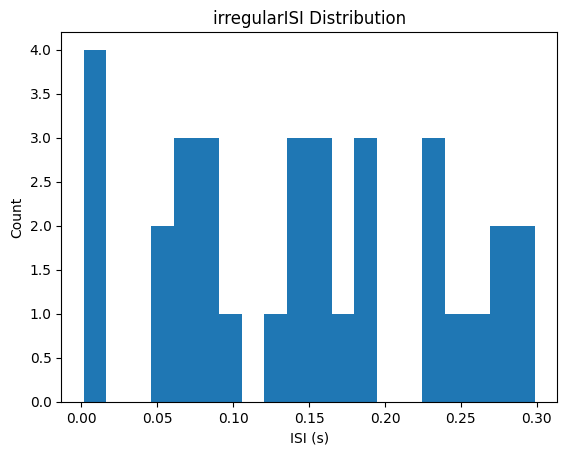

In [9]:
mat.figure()
mat.hist(irregularISI, bins=20)
mat.xlabel("ISI (s)")
mat.ylabel("Count")
mat.title("irregularISI Distribution")
mat.show()


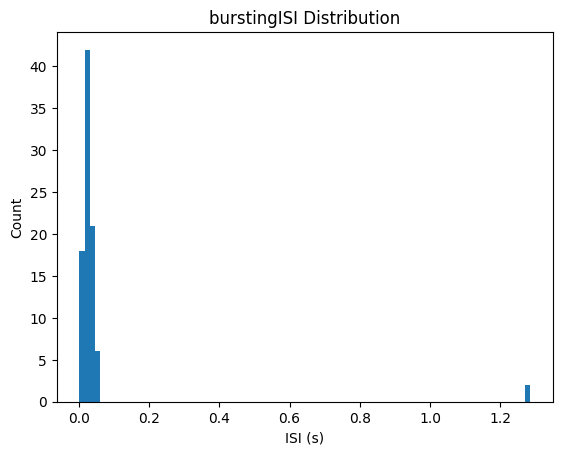

In [10]:
mat.figure()
mat.hist(burstingISI, bins=89)
mat.xlabel("ISI (s)")
mat.ylabel("Count")
mat.title("burstingISI Distribution")
mat.show()


### Mean firing rate (Hz)

The rate is the number of spikes divided by the **5-second recording duration**. This is different from `np.mean(spike_times)`, which returns an average **time**.

In [11]:
print("regular neuron mean firing rate (Hz):", len(regular_spikes) / 5)
print("irregular neuron mean firing rate (Hz):", len(random_spikes) / 5)
print("bursting neuron mean firing rate (Hz):", len(bursting) / 5)


regular neuron mean firing rate (Hz): 5.0
irregular neuron mean firing rate (Hz): 6.8
bursting neuron mean firing rate (Hz): 18.0


### B — scientific interpretation

### Describe the time distribution seen in the raster plot.
In the raster plot, we can see each neuron's firing pattern. For the regular neuron, we can see fixed time intervals; for the irregular neuron, we can see random time intervals; for the bursting neuron, we can see three clusters, with each cluster having the same random time intervals between each firing and fixed time intervals between the starts of the clusters.
### Interpret what each ISI histogram shows.
For the regular neuron's ISI histogram, I can see that all the ISIs are 0.2. That makes sense because I set them all to be 0.2 seconds.
For the irregular neuron, I can see random ISIs because I set them to be random.
For the bursting neuron, I can see a very tall bar between 0-0.05 seconds. This represents the intervals between the firings in each cluster. I can also see a short bar a bit after 1.2 seconds. These are the intervals between clusters.
### Discuss whether mean firing rate alone distinguishes firing patterns.
No, the mean firing rate alone cannot distinguish between the different firing patterns because it doesn't tell us anything about the randomness of the irregular neuron or the long intervals between the clusters in the bursting neuron.
### Choose and calculate additional statistics (e.g., mean ISI, ISI variability) and explain **why** they are useful.
Additional statistics I used are the mean of the ISI of each neuron. This will allow me to check the average time between consecutive spikes. Also, I used the STD of the ISI of each neuron to see how much the ISIs vary around their mean in each neuron.



In [12]:
print("the mean of the regular spikes ISI is", np.round(np.mean(regularISI),3), "the STD of the regular spikes ISI is", np.round(np.std(regularISI),3))

print("the mean of the irregular spikes ISI is", np.round(np.mean(irregularISI),3), "the STD of the irregular spikes ISI is", np.round(np.std(irregularISI),3))

print("the mean of the bursting spikes ISI is", np.round(np.mean(burstingISI),3), "the STD of the bursting spikes ISI is", np.round(np.std(burstingISI),3))

the mean of the regular spikes ISI is 0.2 the STD of the regular spikes ISI is 0.0
the mean of the irregular spikes ISI is 0.145 the STD of the irregular spikes ISI is 0.089
the mean of the bursting spikes ISI is 0.053 the STD of the bursting spikes ISI is 0.187


In the code above, I can learn interesting things about the neurons:

I can see that for the regular neuron, the STD is zero. This means that the ISI for this neuron is fixed, and the mean is 0.2, which shows us that the fixed interval is 0.2 seconds.

I can also see that for the irregular neuron, the STD isn't zero and is around 0.09. We can learn from it that the ISIs indeed vary for this neuron.
Also, we can see that the mean is 0.145.

For the bursting neuron, we see a somewhat large STD number. This can teach us about the "quiet periods" between clusters that make the STD so large. While we see a large STD, the mean for this neuron is the smallest because inside the clusters, the intervals between each firing are very small, and between the clusters, the intervals are huge compared to the intervals between each firing inside the clusters.


## C. Test your assumptions

Assignment requirement: at least three checks, including one **temporal**, one **statistical**, and one **edge-case** check. Explain what each tests and what  you observed.



In the code below, we are checking that all the ISIs are above zero, because if not, then something isn't right. The intervals between spikes aren't supposed to be below zero.

In [13]:
print("regular ISI are positive:", np.all(regularISI > 0))

print("irregular ISI are positive:", np.all(irregularISI > 0))

print("bursting ISI are positive:", np.all(burstingISI > 0))

regular ISI are positive: True
irregular ISI are positive: True
bursting ISI are positive: True


I used the np.all command on the ISI array and checked that every interval in the array is indeed above zero.

In the code below, we are checking that all the STDs are what we expected to see for the regular and irregular neurons. And for the bursting neuron, we are making sure that there are both short intervals (between spikes within each cluster) and long intervals (between each cluster).

In [14]:
print("regular neuron has zero STD:", np.isclose(np.std(regularISI), 0))

print("irregular neuron has positive STD:", np.std(irregularISI) > 0)

print("bursting has short intervals:", np.any(burstingISI < 0.05))

print("bursting has long intervals:", np.any(burstingISI > 1))

regular neuron has zero STD: True
irregular neuron has positive STD: True
bursting has short intervals: True
bursting has long intervals: True


For the regular neuron, I used np.isclose to make sure that the STD for the regular neuron is indeed equal to zero.
For the irregular neuron, I made sure that the STD is above zero because the irregular neuron has random intervals and is supposed to have an STD that is larger than zero.
For the bursting neuron, I used the ISI array and checked that there is indeed at least one short interval and one long interval using the 
np.any command.

Now I need to check if an empty ISI array is considered valid.

In [15]:
emptyISI = np.array([])
print("empty ISI are valid:", len(emptyISI) > 0 and np.all(emptyISI > 0))

empty ISI are valid: False


In the code, I created an empty array that will behave like a neuron that doesn't fire, and checked if the array isn't empty and if there are no intervals that are equal to or below zero. The "and" makes sure that both conditions need to be true in order for the result to be "True". The result is False because the array is empty, so the first condition is False.

## D. Investigate a new realization 
To do this, I will use the code I used to create the firing patterns in question A. I'll use only the irregular and bursting ones because only they are stochastic.

In [16]:
random2 = np.random.default_rng(8)
randomm2 = random2.uniform(0, 0.3, 80)
random_spikes2 = np.cumsum(randomm2)
random_spikes2 = random_spikes2[random_spikes2 <= 5]

print("original irregular spikes:", len(random_spikes))
print("new irregular spikes:", len(random_spikes2))

original irregular spikes: 34
new irregular spikes: 38


We can see that even though we only changed the seed, the new realization contained more spikes during the same 5 seconds.

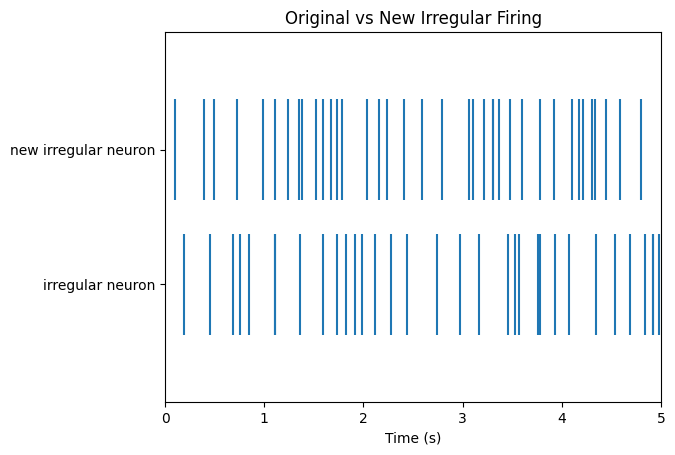

In [17]:
mat.eventplot([random_spikes, random_spikes2],lineoffsets=[1, 3],linelengths=1.5)

mat.xlim(0, 5)
mat.yticks([1, 3],["irregular neuron","new irregular neuron"])
mat.xlabel("Time (s)")
mat.title("Original vs New Irregular Firing")
mat.show()

We can see in the raster plot that while the new firing pattern is still random, the pattern changed and the intervals changed. While the neuron remains irregular, it looks a bit different even though we only changed the seed.

Now we will also change the seed for the bursting neuron and compare it to the original bursting neuron.

In [18]:
burst_random = np.random.default_rng(8)
burst_intervals = burst_random.uniform(0, 0.05, 30)

bursting_new1 = np.cumsum(burst_intervals)
bursting_new2 = bursting_new1 + 2
bursting_new3 = bursting_new2 + 2

bursting_new = np.concatenate((bursting_new1, bursting_new2, bursting_new3))
bursting_new = bursting_new[bursting_new <= 5]

print("original bursting spikes:", len(bursting))
print("new bursting spikes:", len(bursting_new))

original bursting spikes: 90
new bursting spikes: 90


It seems like the number of spikes remains the same in the new neuron. That's interesting. Now let's see if we can see a difference in the raster plot.

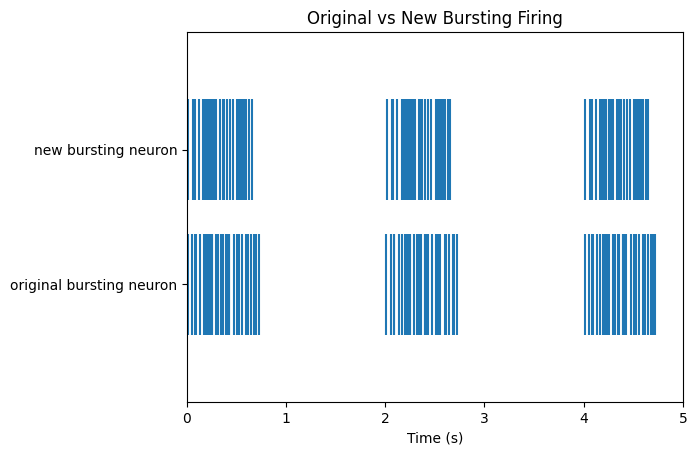

In [19]:
mat.eventplot([bursting, bursting_new], lineoffsets=[1, 3], linelengths=1.5)

mat.xlim(0, 5)
mat.yticks([1, 3], ["original bursting neuron", "new bursting neuron"])
mat.xlabel("Time (s)")
mat.title("Original vs New Bursting Firing")
mat.show()

Here we can see a difference between the original bursting pattern and the new one. For example, the clusters for the new pattern are a bit shorter.

# Conclude by explaining how you would distinguish the three firing patterns based on observations, rather than knowing how they were generated
I can distinguish between the three firing patterns by examining the raster plot containing the three patterns together. The regular neuron will have fixed ISIs, the irregular neuron will have variable ISIs, and the bursting neuron will have visible clusters with quiet periods between them.